# The symbols that disappeared

### Survivorship bias, measured instead of warned about

Everyone doing quantitative finance is told about survivorship bias. Far fewer
have seen the number for a market they care about, because measuring it requires
something most datasets do not have: **the companies that are no longer there.**

That is usually not an oversight. It is how the data gets built. If you assemble a
universe by asking an exchange "what is trading today?" and then pull history for
each name, you have already excluded everything that died. The exclusion is
invisible — nothing errors, nothing is missing, the series just quietly describes a
population of winners.

This dataset was deliberately built the other way. The symbol universe came from
ShareSansar's full company list rather than NEPSE's active board, so it includes
**delisted mutual funds, converted promoter shares, and long-suspended names** that
have not traded in years.

That makes the bias directly measurable. We can run the same calculation twice —
once on survivors only, once on everything — and read off the difference.

> This notebook uses the screening rule derived in
> [notebook 2](02_corporate_actions.ipynb). Returns beyond NEPSE's ~10% daily price
> limit are corporate actions rather than market moves, so they are excluded here.
> Without that step the whole comparison would be measuring bonus issues.

## Setup

In [1]:
import sys; sys.path.insert(0, ".")
from nepse_nb import connect, setup_plots, BLUE, AQUA, ORANGE, CRIMSON, MUTED, INK, GRID
import matplotlib.pyplot as plt
import numpy as np

setup_plots()
con = connect()

# "Alive" = seen on NEPSE's own board in the last month of the pinned snapshot.
con.execute("""
CREATE OR REPLACE VIEW alive AS
SELECT DISTINCT symbol FROM eod_price WHERE business_date >= DATE '2026-08-01'
""")

con.execute("""
CREATE OR REPLACE VIEW life AS
SELECT symbol,
       min(business_date) AS first_seen,
       max(business_date) AS last_seen,
       count(*)           AS trading_days,
       symbol IN (SELECT symbol FROM alive) AS survived
FROM eod_history_ext GROUP BY 1
""")

summary = con.execute("""
    SELECT count(*) AS symbols,
           sum(CASE WHEN survived THEN 1 ELSE 0 END) AS still_trading,
           sum(CASE WHEN survived THEN 0 ELSE 1 END) AS gone
    FROM life
""").df().iloc[0]
print(f"symbols in the 31-year history : {int(summary.symbols)}")
print(f"still trading in Aug 2026      : {int(summary.still_trading)}")
print(f"gone                           : {int(summary.gone)}")
print(f"share that vanished            : {100*summary.gone/summary.symbols:.1f}%")

symbols in the 31-year history : 653
still trading in Aug 2026      : 416
gone                           : 237
share that vanished            : 36.3%


### More than a third of the history is dead companies

If you had built this dataset from NEPSE's active board — the obvious way, and the
way almost everyone does it — you would have silently dropped roughly a third of
the symbols that ever traded.

## When did they disappear?

Delistings are not spread evenly. Let's see the shape.

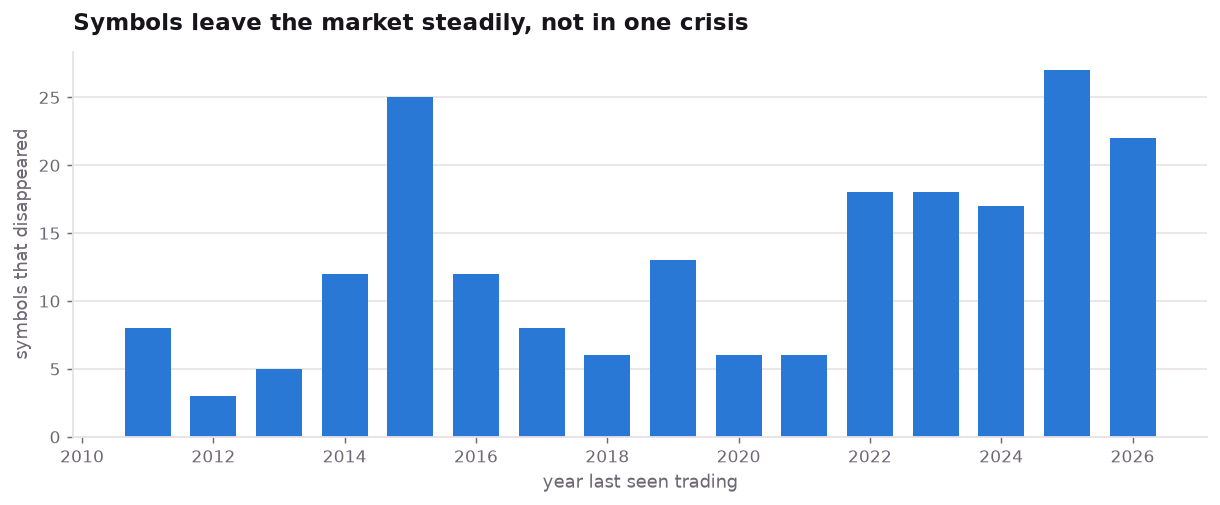

total disappearances: 206
median per year since 2014: 13


In [2]:
deaths = con.execute("""
    SELECT year(last_seen) AS yr, count(*) n
    FROM life WHERE NOT survived AND last_seen < DATE '2026-06-01'
    GROUP BY 1 ORDER BY 1
""").df()

fig, ax = plt.subplots(figsize=(9.5, 4))
ax.bar(deaths.yr, deaths.n, color=BLUE, width=0.7)
ax.set_xlabel("year last seen trading")
ax.set_ylabel("symbols that disappeared")
ax.set_title("Symbols leave the market steadily, not in one crisis")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

print(f"total disappearances: {deaths.n.sum()}")
print(f"median per year since 2014: {deaths[deaths.yr>=2014].n.median():.0f}")

There is no single crash year that removed a cohort. Companies leave NEPSE at a
steady rate of roughly a dozen to two dozen a year, which is precisely the pattern
that makes survivorship bias insidious: it accumulates quietly rather than
announcing itself.

## What kind of company disappears?

Before comparing returns, it is worth knowing whether the two groups are even
comparable. A "disappeared" symbol might be a failed company — or something that
was never a normal listed equity in the first place.

In [3]:
shape = con.execute("""
    SELECT CASE WHEN survived THEN 'survivors' ELSE 'disappeared' END AS grp,
           count(*) n,
           median(trading_days) AS median_trading_days,
           round(median(date_diff('day', first_seen, last_seen) / 365.25), 1) AS median_years_listed
    FROM life GROUP BY 1 ORDER BY 1
""").df()
print(shape.to_string(index=False))

        grp   n  median_trading_days  median_years_listed
disappeared 237                 10.0                  3.3
  survivors 416                793.5                  4.5


That is a striking gap, and it is a warning about the comparison rather than a
result. The median disappeared symbol traded on only a handful of days in its
entire life; the median survivor traded on hundreds.

Many of the dead names are not failed businesses at all — they are **mutual fund
units that reached maturity and closed, and promoter shares that converted into
ordinary shares.** Those are structural instruments with short, thin lives, not
companies that went bust.

This matters for how we interpret everything below. The comparison is between two
genuinely different populations, and pretending otherwise would overstate the case.

In [4]:
examples = con.execute("""
    SELECT symbol, first_seen, last_seen, trading_days
    FROM life WHERE NOT survived AND trading_days > 200
    ORDER BY trading_days DESC LIMIT 10
""").df()
print("Substantial companies that disappeared (not short-lived instruments):\n")
print(examples.to_string(index=False))

Substantial companies that disappeared (not short-lived instruments):

symbol first_seen  last_seen  trading_days
   PFL 2011-05-25 2026-07-09          2598
  KRBL 2011-03-20 2024-12-24          2583
  SFCL 2011-03-25 2026-07-09          1837
NABILP 2011-05-31 2026-03-31          1566
   NEF 2017-02-05 2023-11-01          1488
 NIBPO 2012-04-02 2023-01-10          1474
  SAEF 2018-03-04 2024-12-22          1441
 NICGF 2018-04-24 2025-03-09          1427
NMBHF1 2017-01-25 2023-10-12          1422
  CMF1 2018-04-24 2025-02-27          1407


These are the ones that matter for bias: names with years of real trading history
that simply are not there any more. `KRBL` alone carries over 2,500 sessions.

## Measuring the bias

Now the comparison. For every symbol we compute daily returns, **screening out
moves beyond the 10.5% circuit limit** as established in notebook 2, then take the
equal-weighted mean return across two universes:

- **survivors only** — what you get if you build a universe from today's board
- **everything** — what actually happened, dead companies included

We restrict to 2016 onward, where the market has enough breadth to be worth
studying.

In [5]:
con.execute("""
CREATE OR REPLACE VIEW rets AS
WITH s AS (
    SELECT symbol, business_date, CAST(close_price AS DOUBLE) c,
           lag(CAST(close_price AS DOUBLE)) OVER (PARTITION BY symbol ORDER BY business_date) pc
    FROM eod_history_ext WHERE close_price > 0
)
SELECT symbol, business_date, (c - pc)/pc AS ret
FROM s
WHERE pc > 0 AND abs((c - pc)/pc) <= 0.105      -- notebook 2's screen
""")

cmp = con.execute("""
    SELECT CASE WHEN l.survived THEN 'survivors only' ELSE 'disappeared' END AS universe,
           count(DISTINCT r.symbol) symbols, count(*) observations,
           100 * avg(r.ret) * 252 AS annualised_pct
    FROM rets r JOIN life l USING (symbol)
    WHERE r.business_date >= DATE '2016-01-01'
    GROUP BY 1
    UNION ALL
    SELECT 'ALL (unbiased)', count(DISTINCT r.symbol), count(*), 100 * avg(r.ret) * 252
    FROM rets r WHERE r.business_date >= DATE '2016-01-01'
""").df()
print(cmp.to_string(index=False))

surv = float(cmp.loc[cmp.universe == 'survivors only', 'annualised_pct'].iloc[0])
allu = float(cmp.loc[cmp.universe == 'ALL (unbiased)', 'annualised_pct'].iloc[0])
dead = float(cmp.loc[cmp.universe == 'disappeared', 'annualised_pct'].iloc[0])
print(f"\nsurvivorship bias = {surv - allu:+.2f} percentage points per year")
print(f"survivor vs dead gap = {surv - dead:+.2f} percentage points per year")

      universe  symbols  observations  annualised_pct
survivors only      414        434786       21.489687
   disappeared      161         29014        9.664071
ALL (unbiased)      575        463800       20.749911

survivorship bias = +0.74 percentage points per year
survivor vs dead gap = +11.83 percentage points per year


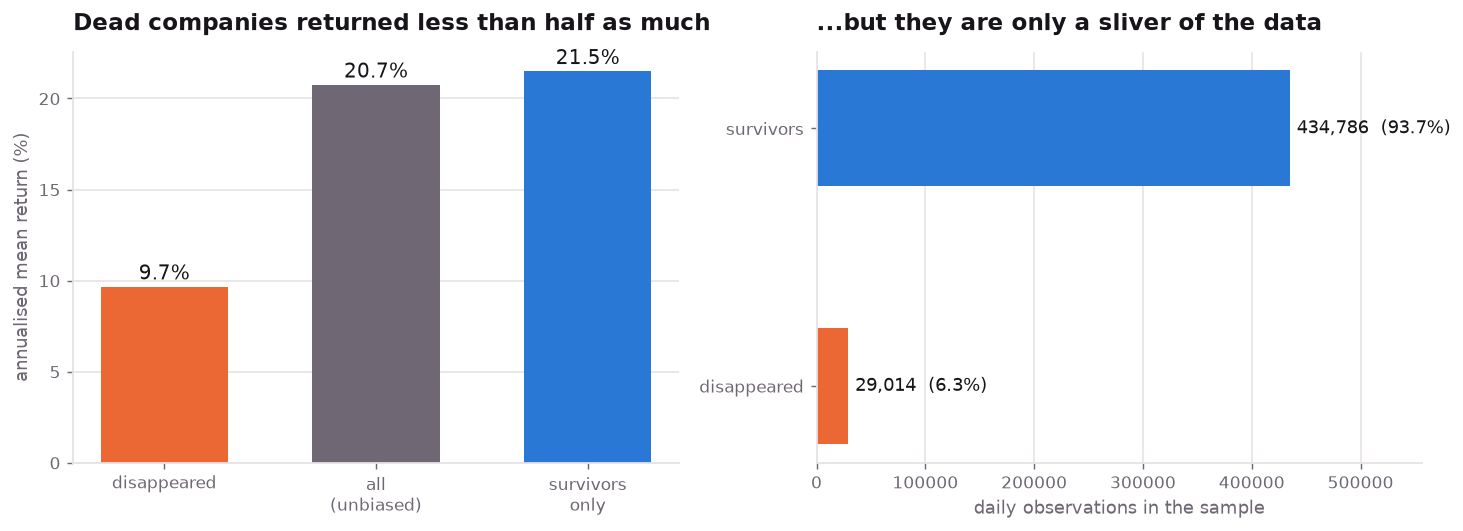

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.2), gridspec_kw={"width_ratios": [1, 1]})

order = ['disappeared', 'ALL (unbiased)', 'survivors only']
vals = [float(cmp.loc[cmp.universe == u, 'annualised_pct'].iloc[0]) for u in order]
cols = [ORANGE, MUTED, BLUE]
bars = ax1.bar(range(3), vals, color=cols, width=0.6)
ax1.set_xticks(range(3)); ax1.set_xticklabels(['disappeared', 'all\n(unbiased)', 'survivors\nonly'])
ax1.set_ylabel("annualised mean return (%)")
ax1.set_title("Dead companies returned less than half as much")
ax1.grid(axis="x", visible=False)
for b, v in zip(bars, vals):
    ax1.text(b.get_x() + b.get_width()/2, v + 0.4, f"{v:.1f}%", ha="center",
             fontsize=11, color=INK)

obs = [int(cmp.loc[cmp.universe == u, 'observations'].iloc[0]) for u in ['disappeared', 'survivors only']]
ax2.barh(['disappeared', 'survivors'], obs, color=[ORANGE, BLUE], height=0.45)
for i, o in enumerate(obs):
    ax2.text(o + max(obs)*0.015, i, f"{o:,}  ({100*o/sum(obs):.1f}%)", va="center",
             fontsize=10, color=INK)
ax2.set_xlabel("daily observations in the sample")
ax2.set_title("...but they are only a sliver of the data")
ax2.set_xlim(0, max(obs) * 1.28)
ax2.grid(axis="y", visible=False)

plt.tight_layout()
plt.show()

### The finding, and why it is smaller than you might expect

Two numbers, and the second explains the first:

- Companies that disappeared returned **less than half** what survivors did. The
  per-symbol gap is enormous.
- But the aggregate bias is **under one percentage point per year**.

Those are consistent, not contradictory. Dead symbols account for only a few
percent of all daily observations, because they were thin and short-lived by
nature. A large gap applied to a small weight produces a modest aggregate effect.

That is the real lesson, and it generalises beyond Nepal: **the size of
survivorship bias depends on the weight of the excluded population, not just on how
badly it performed.** A textbook warning that stops at "survivors did better" tells
you the sign and not the magnitude — and the magnitude is what decides whether you
need to care.

Under one point a year is not nothing. Compounded over the decade in this sample it
is a meaningful distortion, and it is entirely avoidable if the dead names are in
your universe.

## When it would bite harder

The aggregate number understates the risk for particular strategies. Anything that
**selects on the characteristics of dying companies** concentrates exposure in
exactly the population we just measured: deep-value screens on collapsing prices,
small-cap tilts, and mean-reversion strategies that buy the worst performers.

Weighting also matters. This was equal-weighted; a value-weighted calculation would
shrink the bias further because dying companies are small. The bias is largest
precisely where a naive backtest looks most attractive.

## What to take away

1. **A third of the symbols that ever traded on NEPSE are gone**, and a
   universe built from today's board silently excludes every one of them.
2. Delistings are a steady drip of a dozen-plus a year, not a single crisis.
3. Survivors out-earned the disappeared by a wide margin per symbol, but the
   aggregate bias is **under 1 percentage point a year** because dead names are a
   small share of observations.
4. Many "disappeared" symbols are matured mutual funds and converted promoter
   shares rather than failed businesses — the two populations are not
   like-for-like, and saying so is part of reporting the result honestly.

If you use this dataset: the `eod_history_ext` table contains the dead symbols. Do
not filter to currently-trading names unless you specifically want a survivor
universe, and if you do, say so in your write-up.

---

**Back to:** [The broker network](01_broker_network.ipynb) ·
[The corporate actions trap](02_corporate_actions.ipynb)